# ### **Goal: To analyze the relationship between app popularity, user ratings, and app categories to identify high-performing categories in the Google Play Store.**

In [ ]:
from pyspark.sql.functions import (
    col, regexp_replace, when, to_date, to_timestamp,
    count, mean, stddev, min as spark_min, max as spark_max,
    countDistinct, desc, asc, round as spark_round, isnan, isnull,
    datediff, current_date, year, month, lit, sum as spark_sum
)

In [ ]:
df = spark.read.csv(
    "s3://amzn-s3-bigdata-etl-project/customer-dataCSV-incoming/Google-Playstore.csv",
    header=True,
    inferSchema=True
)

df.show(5)


+--------------------+--------------------+-------------+------+------------+--------+----------------+----------------+----+-----+--------+----+---------------+--------------------+--------------------+--------------------+------------+------------+--------------+--------------------+------------+----------------+--------------+-------------------+
|            App Name|              App Id|     Category|Rating|Rating Count|Installs|Minimum Installs|Maximum Installs|Free|Price|Currency|Size|Minimum Android|        Developer Id|   Developer Website|     Developer Email|    Released|Last Updated|Content Rating|      Privacy Policy|Ad Supported|In App Purchases|Editors Choice|       Scraped Time|
+--------------------+--------------------+-------------+------+------------+--------+----------------+----------------+----+-----+--------+----+---------------+--------------------+--------------------+--------------------+------------+------------+--------------+--------------------+----------

In [ ]:
df.printSchema()

root
 |-- App Name: string (nullable = true)
 |-- App Id: string (nullable = true)
 |-- Category: string (nullable = true)
 |-- Rating: string (nullable = true)
 |-- Rating Count: string (nullable = true)
 |-- Installs: string (nullable = true)
 |-- Minimum Installs: string (nullable = true)
 |-- Maximum Installs: string (nullable = true)
 |-- Free: string (nullable = true)
 |-- Price: string (nullable = true)
 |-- Currency: string (nullable = true)
 |-- Size: string (nullable = true)
 |-- Minimum Android: string (nullable = true)
 |-- Developer Id: string (nullable = true)
 |-- Developer Website: string (nullable = true)
 |-- Developer Email: string (nullable = true)
 |-- Released: string (nullable = true)
 |-- Last Updated: string (nullable = true)
 |-- Content Rating: string (nullable = true)
 |-- Privacy Policy: string (nullable = true)
 |-- Ad Supported: string (nullable = true)
 |-- In App Purchases: string (nullable = true)
 |-- Editors Choice: string (nullable = true)
 |-- Scra

In [ ]:
from pyspark.sql.functions import col

df_clean = df.select(
    col("App Name").alias("app_name"),
    col("App Id").alias("app_id"),
    col("Category").alias("category"),
    col("Rating").alias("rating"),
    col("Rating Count").alias("rating_count"),
    col("Installs").alias("installs"),
    col("Minimum Installs").alias("min_installs"),
    col("Maximum Installs").alias("max_installs"),
    col("Free").alias("is_free"),
    col("Price").alias("price"),
    col("Currency").alias("currency"),
    col("Size").alias("size"),
    col("Minimum Android").alias("min_android"),
    col("Developer Id").alias("developer_id"),
    col("Developer Website").alias("developer_website"),
    col("Developer Email").alias("developer_email"),
    col("Released").alias("released"),
    col("Last Updated").alias("last_updated"),
    col("Content Rating").alias("content_rating"),
    col("Privacy Policy").alias("privacy_policy"),
    col("Ad Supported").alias("ad_supported"),
    col("In App Purchases").alias("in_app_purchases"),
    col("Editors Choice").alias("editors_choice"),
    col("Scraped Time").alias("scraped_time")
)


In [ ]:
df_clean.show(5)


+--------------------+--------------------+-------------+------+------------+--------+------------+------------+-------+-----+--------+----+------------+--------------------+--------------------+--------------------+------------+------------+--------------+--------------------+------------+----------------+--------------+-------------------+
|            app_name|              app_id|     category|rating|rating_count|installs|min_installs|max_installs|is_free|price|currency|size| min_android|        developer_id|   developer_website|     developer_email|    released|last_updated|content_rating|      privacy_policy|ad_supported|in_app_purchases|editors_choice|       scraped_time|
+--------------------+--------------------+-------------+------+------------+--------+------------+------------+-------+-----+--------+----+------------+--------------------+--------------------+--------------------+------------+------------+--------------+--------------------+------------+----------------+----

In [ ]:
from pyspark.sql.functions import regexp_replace
from pyspark.sql.functions import expr
df_clean = df_clean \
    .withColumn("rating", col("rating").try_cast("double")) \
    .withColumn("rating_count", col("rating_count").try_cast("int")) \
    .withColumn("installs",
        regexp_replace(col("installs"), "[+,]", "")) \
    .withColumn("min_installs", col("min_installs").try_cast("int")) \
    .withColumn("max_installs", col("max_installs").try_cast("int"))


In [ ]:
df_clean = df_clean.withColumn(
    "price_clean",
    col("price").cast("double")
)


In [ ]:
from pyspark.sql.functions import when

bool_cols = ["is_free", "ad_supported", "in_app_purchases", "editors_choice"]

for c in bool_cols:
    df_clean = df_clean.withColumn(
        c,
        when(col(c) == "True", True)
        .when(col(c) == "False", False)
        .otherwise(None)
    )


In [ ]:
from pyspark.sql import functions as F

df_clean = df_clean \
    .withColumn("released_date", F.expr("try_to_date(released, 'MMM d, yyyy')")) \
    .withColumn("last_updated_date", F.expr("try_to_date(last_updated, 'MMM d, yyyy')"))

In [ ]:
display(df_clean.select(
    "app_name",
    "category",
    "rating",
    "rating_count",
    "installs",
    "price_clean",
    "is_free",
    "released_date"
).limit(5))


app_name,category,rating,rating_count,installs,price_clean,is_free,released_date
Gakondo,Adventure,0.0,0,10,0.0,true,2020-02-26
Ampere Battery Info,Tools,4.4,64,5000,0.0,true,2020-05-21
Vibook,Productivity,0.0,0,50,0.0,true,2019-08-09
Smart City Trichy Public Service Vehicles 17UCS548,Communication,5.0,5,10,0.0,true,2018-09-10
GROW.me,Tools,0.0,0,100,0.0,true,2020-02-21


In [ ]:
# Add derived features
df_clean = df_clean \
    .withColumn("days_since_release", datediff(current_date(), col("released_date"))) \
    .withColumn("days_since_update", datediff(current_date(), col("last_updated_date"))) \
    .withColumn("release_year", year(col("released_date"))) \
    .withColumn("update_year", year(col("last_updated_date")))

In [ ]:
print("\n AFTER DATA TYPE CONVERSIONS ")
df_clean.printSchema()
df_clean.select("rating", "installs", "price_clean", "is_free", "released_date").show(5)


 AFTER DATA TYPE CONVERSIONS 
root
 |-- app_name: string (nullable = true)
 |-- app_id: string (nullable = true)
 |-- category: string (nullable = true)
 |-- rating: double (nullable = true)
 |-- rating_count: integer (nullable = true)
 |-- installs: string (nullable = true)
 |-- min_installs: integer (nullable = true)
 |-- max_installs: integer (nullable = true)
 |-- is_free: boolean (nullable = true)
 |-- price: string (nullable = true)
 |-- currency: string (nullable = true)
 |-- size: string (nullable = true)
 |-- min_android: string (nullable = true)
 |-- developer_id: string (nullable = true)
 |-- developer_website: string (nullable = true)
 |-- developer_email: string (nullable = true)
 |-- released: string (nullable = true)
 |-- last_updated: string (nullable = true)
 |-- content_rating: string (nullable = true)
 |-- privacy_policy: string (nullable = true)
 |-- ad_supported: boolean (nullable = true)
 |-- in_app_purchases: boolean (nullable = true)
 |-- editors_choice: boolea

In [ ]:
df_clean.show(5)

+--------------------+--------------------+-------------+------+------------+--------+------------+------------+-------+-----+--------+----+------------+--------------------+--------------------+--------------------+------------+------------+--------------+--------------------+------------+----------------+--------------+-------------------+-----------+-------------+-----------------+------------------+-----------------+------------+-----------+
|            app_name|              app_id|     category|rating|rating_count|installs|min_installs|max_installs|is_free|price|currency|size| min_android|        developer_id|   developer_website|     developer_email|    released|last_updated|content_rating|      privacy_policy|ad_supported|in_app_purchases|editors_choice|       scraped_time|price_clean|released_date|last_updated_date|days_since_release|days_since_update|release_year|update_year|
+--------------------+--------------------+-------------+------+------------+--------+------------+-

**EXPLORATORY DATA ANALYSIS (EDA)**



This starts the EDA section. We summarize app performance by category using three signals:
- Popularity: installs and rating_count
- Satisfaction: rating
- Supply: how many apps exist in each category

Question to answer:
Which categories combine high popularity and high user satisfaction, and how do they compare to crowded categories?

- Counts how many apps are in each category.

Why it matters for the goal:
- It tells us which categories are most crowded. High-performing categories are not only about installs and ratings, but also competition.

Question to answer:
Which categories are most crowded, and do crowded categories also have strong ratings or installs?

In [ ]:
from pyspark.sql.functions import count

apps_per_category = (
    df_clean
    .filter(df_clean.category.isNotNull())
    .groupBy("category")
    .agg(count("*").alias("num_apps"))
    .orderBy("num_apps", ascending=False)
)

display(apps_per_category)


category,num_apps
Education,241086
Music & Audio,154905
Tools,143987
Business,143770
Entertainment,138271
Lifestyle,118331
Books & Reference,116726
Personalization,89210
Health & Fitness,83510
Productivity,79695


- Computes the average rating per category.

Why it matters for the goal:
- Average rating is a direct proxy for user satisfaction, one axis of "high-performing" categories.

Question to answer:
Which categories have the highest average user ratings, and are they also popular?

In [ ]:
from pyspark.sql.functions import avg

avg_rating_per_category = (
    df_clean
    .filter(
        (df_clean.category.isNotNull()) &
        (df_clean.rating.isNotNull())
    )
    .groupBy("category")
    .agg(avg("rating").alias("avg_rating"))
    .orderBy("avg_rating", ascending=False)
)

display(avg_rating_per_category)


category,avg_rating
Role Playing,3.3844982913948454
Casino,3.2796822244289974
Simulation,3.2108871677521567
Weather,3.120294530154278
Card,3.0851603281133477
Racing,2.9602338606662095
Video Players & Editors,2.903842010771992
Word,2.9020762463343104
Strategy,2.878900084982398
Comics,2.864906061680254


- Sums max_installs by category to estimate total category installs.

Why it matters for the goal:
- Total installs is your main popularity metric at the category level.

Question to answer:
Which categories drive the most installs, and how do their ratings compare to less popular categories?

In [ ]:
from pyspark.sql.functions import sum

installs_per_category = (
    df_clean
    .filter(
        (df_clean.category.isNotNull()) &
        (df_clean.max_installs.isNotNull())
    )
    .groupBy("category")
    .agg(sum("max_installs").alias("total_installs"))
    .orderBy("total_installs", ascending=False)
)

display(installs_per_category)


category,total_installs
Tools,73532934161
Productivity,35688338257
Action,30742136749
Casual,30525269577
Entertainment,27939346236
Communication,27908388294
Photography,25836779557
Arcade,25681896317
Music & Audio,23021925013
Simulation,19957063168


- Computes the average rating_count per category.

Why it matters for the goal:
- rating_count is a proxy for engagement and confidence. A high average rating with very low rating_count can be less reliable.

Question to answer:
Which categories have the strongest engagement (high rating_count), and do they also maintain high ratings?

In [ ]:
avg_rating_count_per_category = (
    df_clean
    .filter(
        (df_clean.category.isNotNull()) &
        (df_clean.rating_count.isNotNull())
    )
    .groupBy("category")
    .agg(avg("rating_count").alias("avg_rating_count"))
    .orderBy("avg_rating_count", ascending=False)
)

display(avg_rating_count_per_category)


category,avg_rating_count
Strategy,28328.30302294525
Action,20805.240093935216
Video Players & Editors,19028.56014362657
Racing,17798.806229733713
Role Playing,14559.170446308377
Social,10679.852530481574
Simulation,10155.266854427038
Communication,9886.983215900726
Casino,9692.946375372394
Casual,7296.491869175955


- Breaks down the number of free vs paid apps by category.

Why it matters for the goal:
- Monetization model can relate to popularity and ratings. Some categories may perform better when free, others may support paid apps.

Question to answer:
In high-performing categories, is the app market mostly free or paid, and does that relate to ratings or installs?

In [ ]:
free_paid_distribution = (
    df_clean
    .filter(
        (df_clean.category.isNotNull()) &
        (df_clean.is_free.isNotNull())
    )
    .groupBy("category", "is_free")
    .agg(count("*").alias("app_count"))
    .orderBy("category", "is_free")
)

display(free_paid_distribution)


category,is_free,app_count
Action,false,597
Action,true,26958
Adventure,false,986
Adventure,true,22217
Arcade,false,766
Arcade,true,53026
Art & Design,false,174
Art & Design,true,18365
Auto & Vehicles,false,284
Auto & Vehicles,true,17996


- Uses a window to rank apps within each category by max_installs (then rating).
- Selects the top ranked app per category.

Why it matters for the goal:
- Helps identify category leaders and whether category success is dominated by a single outlier app.

Question to answer:
Do high-performing categories have one dominant app, or many apps sharing installs and ratings?

In [ ]:
from pyspark.sql.window import Window
from pyspark.sql.functions import row_number, col

window_spec = Window.partitionBy("category").orderBy(
    col("max_installs").desc(),
    col("rating").desc()
)

top_apps = (
    df_clean
    .filter(
        col("category").isNotNull() &
        col("rating").isNotNull() &
        col("max_installs").isNotNull()
    )
    .withColumn("rank", row_number().over(window_spec))
    .filter(col("rank") == 1)
    .select("category", "app_name", "rating", "max_installs")
)

display(top_apps)


category,app_name,rating,max_installs
Action,Garena Free Fire - Rampage,4.2,976536041
Adventure,Roblox,4.4,427633153
Arcade,Subway Surfers,4.6,1704495994
Art & Design,"Canva: Graphic Design, Video Collage, Logo Maker",4.7,134619454
Auto & Vehicles,Android Auto,4.3,1976625745
Beauty,Perfect365: One-Tap Makeover,4.3,53849836
Board,Ludo King™,4.2,589524427
Books & Reference,Amazon Kindle,4.7,373230108
Business,Secure Folder,4.2,1410817280
Card,Solitaire,4.5,129283628


- Converts the top app per category to Pandas and plots a bar chart of max_installs by category.

Why it matters for the goal:
- Visual comparison makes it easier to spot categories where the leading app is extremely popular.

Question to answer:
Which categories have an exceptionally dominant top app, and are those categories also high-rated?

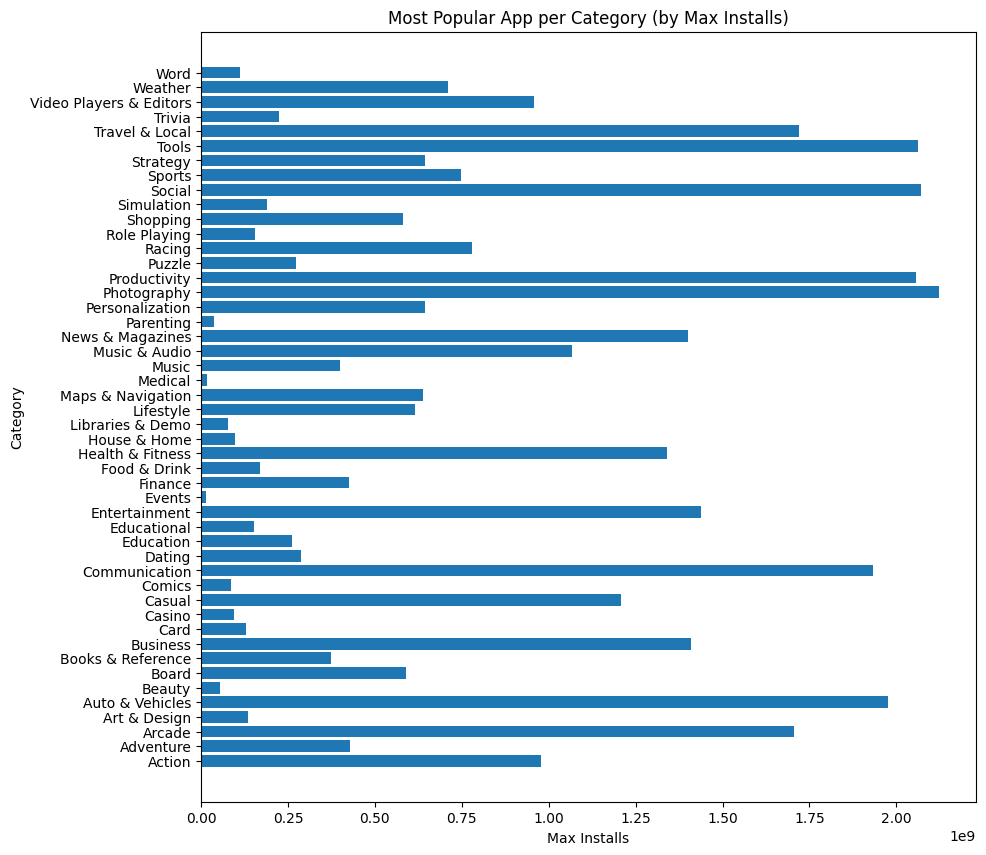

In [ ]:
import matplotlib.pyplot as plt

top_apps_pd = top_apps.toPandas()

plt.figure(figsize=(10,10))
plt.barh(top_apps_pd["category"], top_apps_pd["max_installs"])
plt.xlabel("Max Installs")
plt.ylabel("Category")
plt.title("Most Popular App per Category (by Max Installs)")
plt.show()


- Aggregates each category into (total installs, average rating).
- Plots a scatter chart (log scale installs) and labels categories.

Why it matters for the goal:
- This is the core popularity vs satisfaction view for identifying "high-performing" categories.

Question to answer:
Which categories sit in the top-right region (high installs and high ratings), and which categories are popular but low-rated?

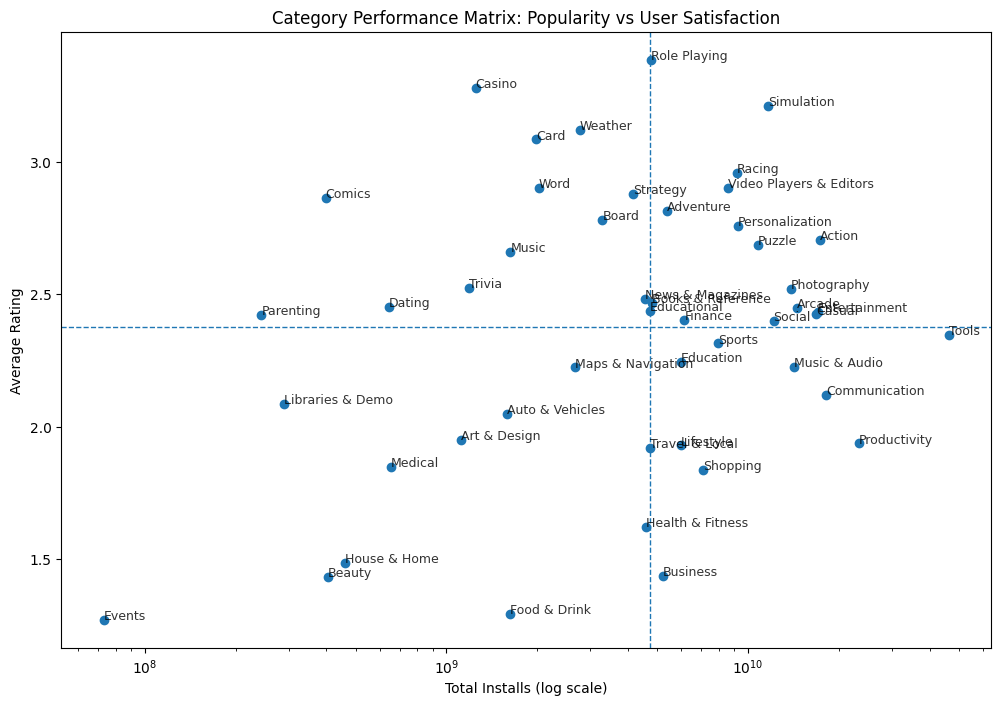

In [ ]:
import matplotlib.pyplot as plt

# Reuse the same aggregated data
category_perf = (
    df_clean
    .filter(
        col("category").isNotNull() &
        col("rating").isNotNull() &
        col("min_installs").isNotNull()
    )
    .groupBy("category")
    .agg(
        avg("rating").alias("avg_rating"),
        sum("min_installs").alias("total_installs")
    )
    .toPandas()
)

plt.figure(figsize=(12, 8))

# Scatter plot
plt.scatter(
    category_perf["total_installs"],
    category_perf["avg_rating"]
)

# Log scale for installs (better readability)
plt.xscale("log")

# Axis labels and title
plt.xlabel("Total Installs (log scale)")
plt.ylabel("Average Rating")
plt.title("Category Performance Matrix: Popularity vs User Satisfaction")

# Add category labels to each point
for i, row in category_perf.iterrows():
    plt.text(
        row["total_installs"],
        row["avg_rating"],
        row["category"],
        fontsize=9,
        alpha=0.8
    )

# Add reference lines (visual guidance)
plt.axhline(
    category_perf["avg_rating"].mean(),
    linestyle="--",
    linewidth=1
)

plt.axvline(
    category_perf["total_installs"].median(),
    linestyle="--",
    linewidth=1
)

plt.show()


- Builds a summary table per category: app_count, avg_rating, avg_installs.
- Prints the top 10 categories by app_count.

Why it matters for the goal:
- Lets you compare crowded categories with their quality and popularity averages.

Question to answer:
Are the largest categories also the best performing, or do smaller categories achieve higher ratings or installs?

In [ ]:
# Category Analysis
print("\n TOP 10 CATEGORIES BY APP COUNT ")
category_stats = df_clean.groupBy("category") \
    .agg(
        count("*").alias("app_count"),
        spark_round(mean("rating"), 2).alias("avg_rating"),
        spark_round(mean("max_installs"), 0).alias("avg_installs")
    ) \
    .orderBy(desc("app_count"))

category_stats.show(10)


 TOP 10 CATEGORIES BY APP COUNT 
+-----------------+---------+----------+------------+
|         category|app_count|avg_rating|avg_installs|
+-----------------+---------+----------+------------+
|        Education|   241086|      2.25|     44855.0|
|    Music & Audio|   154905|      2.23|    148620.0|
|            Tools|   143987|      2.35|    510713.0|
|         Business|   143770|      1.44|     59663.0|
|    Entertainment|   138271|      2.44|    202064.0|
|        Lifestyle|   118331|      1.93|     86988.0|
|Books & Reference|   116726|      2.47|     60884.0|
|  Personalization|    89210|      2.76|    171714.0|
| Health & Fitness|    83510|      1.62|     96616.0|
|     Productivity|    79695|      1.94|    447823.0|
+-----------------+---------+----------+------------+
only showing top 10 rows


- Shows the distribution of ratings.
- Buckets apps into rating ranges and counts how many apps fall into each range.

Why it matters for the goal:
- Helps interpret whether category averages are driven by many medium apps or a smaller set of highly rated apps.

Question to answer:
Is the store dominated by high-rated apps, or are ratings mostly average, and how might this affect category comparisons?

In [ ]:
#Rating Analysis
print("\n RATING DISTRIBUTION")
df_clean.groupBy("rating") \
    .agg(count("*").alias("count")) \
    .orderBy("rating") \
    .show(20)

print("\n APPS BY RATING RANGE")
df_clean.withColumn(
    "rating_range",
    when(col("rating") >= 4.5, "Excellent (4.5-5.0)")
    .when(col("rating") >= 4.0, "Good (4.0-4.5)")
    .when(col("rating") >= 3.0, "Average (3.0-4.0)")
    .when(col("rating") >= 2.0, "Below Average (2.0-3.0)")
    .otherwise("Poor (< 2.0)")
) \
.groupBy("rating_range") \
.agg(count("*").alias("count")) \
.orderBy(desc("count")) \
.show()


 RATING DISTRIBUTION
+------+-------+
|rating|  count|
+------+-------+
|  NULL|  22913|
|   0.0|1059751|
|   1.0|    713|
|   1.1|    236|
|   1.2|    531|
|   1.3|    579|
|   1.4|   1011|
|   1.5|   1157|
|   1.6|   1644|
|   1.7|   1928|
|   1.8|   2957|
|   1.9|   2588|
|   2.0|   3804|
|   2.1|   3675|
|   2.2|   4954|
|   2.3|   5414|
|   2.4|   6051|
|   2.5|   6942|
|   2.6|   9213|
|   2.7|   9200|
+------+-------+
only showing top 20 rows

 APPS BY RATING RANGE
+--------------------+-------+
|        rating_range|  count|
+--------------------+-------+
|        Poor (< 2.0)|1096008|
| Excellent (4.5-5.0)| 423003|
|      Good (4.0-4.5)| 394632|
|   Average (3.0-4.0)| 326291|
|Below Average (2....|  73010|
+--------------------+-------+



- Shows the most common install levels (based on max_installs) and counts apps in each level.

Why it matters for the goal:
- Installs are usually heavy-tailed. Understanding the distribution helps interpret category totals and outliers.

Question to answer:
Are installs concentrated in a small number of very popular apps, and does that vary by category?

In [ ]:
from pyspark.sql.functions import count, desc

print("\nINSTALL DISTRIBUTION (TOP 15)")
(
    df_clean
    .groupBy("max_installs")
    .agg(count("*").alias("app_count"))
    .orderBy(desc("app_count"))
    .show(15)
)



INSTALL DISTRIBUTION (TOP 15)
+------------+---------+
|max_installs|app_count|
+------------+---------+
|           3|    16815|
|           2|    16623|
|           4|    16319|
|           6|    15842|
|           5|    15695|
|           1|    15605|
|           7|    14942|
|           8|    14142|
|          10|    13606|
|           9|    13154|
|          11|    12524|
|          12|    11861|
|           0|    11589|
|          13|    11362|
|          14|    11124|
+------------+---------+
only showing top 15 rows


- Lists the top 20 most installed apps, with category and rating.

Why it matters for the goal:
- Shows which categories dominate the very top of the popularity distribution.

Question to answer:
Which categories appear most often among the top installed apps, and do those apps also have strong ratings?

In [ ]:
print("\nTOP 20 MOST INSTALLED APPS")

(
    df_clean
    .select("app_name", "category", "max_installs", "rating")
    .filter(
        col("app_name").isNotNull() &
        col("category").isNotNull() &
        col("max_installs").isNotNull()
    )
    .orderBy(desc("max_installs"), desc("rating"))
    .show(20, truncate=False)
)



TOP 20 MOST INSTALLED APPS
+--------------------------------------------------+---------------+------------+------+
|app_name                                          |category       |max_installs|rating|
+--------------------------------------------------+---------------+------------+------+
|Samsung Gallery                                   |Photography    |2123105347  |4.5   |
|Facebook Lite                                     |Social         |2072296494  |3.1   |
|Samsung My Files                                  |Tools          |2063336389  |4.3   |
|Microsoft OneDrive                                |Productivity   |2056017889  |4.5   |
|Android Auto                                      |Auto & Vehicles|1976625745  |4.3   |
|Messages                                          |Communication  |1931517750  |4.4   |
|Carrier Services                                  |Communication  |1793502218  |4.3   |
|Skype - free IM & video calls                     |Communication  |1769991234  |4

- For the top 10 categories by app_count, computes correlation between rating and max_installs.

Why it matters for the goal:
- It tests whether higher user satisfaction is associated with higher popularity inside each category.

Question to answer:
In which categories do ratings and installs move together, and in which categories is popularity weakly related to ratings?

In [ ]:
print("\n CORRELATION: RATING VS INSTALLS (TOP CATEGORIES) ")

top_categories = [
    row["category"]
    for row in category_stats.select("category").limit(10).collect()
]

for cat in top_categories:
    cat_data = (
        df_clean.filter(col("category") == cat)
        .select("rating", "max_installs")
        .filter(col("rating").isNotNull() & col("max_installs").isNotNull())
    )
    if cat_data.count() > 0:
        correlation = cat_data.stat.corr("rating", "max_installs")
        print(f"{cat}: {correlation:.4f}")


 CORRELATION: RATING VS INSTALLS (TOP CATEGORIES) 
Education: 0.0373
Music & Audio: 0.0211
Tools: 0.0295
Business: 0.0163
Entertainment: 0.0266
Lifestyle: 0.0305
Books & Reference: 0.0323
Personalization: 0.0296
Health & Fitness: 0.0239
Productivity: 0.0266



This marks the transition from analysis to saving outputs. The saved dataset can be reused for dashboards, ML, or downstream reporting.

SAVE CLEANED DATA TO DELTA/PARQUET


- Drops price columns (to avoid malformed values during writes).
- Writes the cleaned dataset to Parquet.

Why it matters:
- Produces a reusable curated dataset for later analysis, and avoids write failures caused by invalid numeric casts.

Note:
- Spark writes Parquet as a folder of part files, which is normal.

In [ ]:
df_to_save = df_clean.drop("price", "price_clean")

output_path_parquet = "s3://amzn-s3-bigdata-etl-project/cleaned-data/google-playstore-parquet-no-price"
df_to_save.write.mode("overwrite").parquet(output_path_parquet)

print("Saved Parquet to:", output_path_parquet)

Saved Parquet to: s3://amzn-s3-bigdata-etl-project/cleaned-data/google-playstore-parquet-no-price



Phase 2 focuses on performance. We optimize only the parts that showed bottlenecks during EDA:
- repeated groupBy aggregations by category
- per-category loops that trigger many Spark jobs
- window operations that require sorting
- skew in category counts

##  **phase 2: opimization**

### Optimization comment and justification

Optimization applied:
- Combine multiple category aggregations into a single groupBy job.

Justification:
- In the original EDA, similar groupBy(category) aggregations were run in separate cells, causing repeated shuffles.
- GroupBy triggers a shuffle. Fewer shuffles usually means lower runtime and fewer spill events.
- This cell builds a single metrics table that can be sorted different ways without recomputing.

In [ ]:
from pyspark.sql import functions as F

# Keep only the columns needed for category-level analysis (reduces shuffle and serialization work)
df_eda = (
    df_clean
    .select("category", "app_name", "rating", "rating_count", "max_installs", "is_free")
    .filter(F.col("category").isNotNull())
)

category_metrics = (
    df_eda
    .groupBy("category")
    .agg(
        F.count("*").alias("num_apps"),
        F.avg("rating").alias("avg_rating"),
        F.avg("rating_count").alias("avg_rating_count"),
        F.sum("max_installs").alias("total_installs")
    )
)

display(category_metrics.orderBy(F.desc("num_apps")))
display(category_metrics.orderBy(F.desc("total_installs")))
display(category_metrics.orderBy(F.desc("avg_rating")))


category,num_apps,avg_rating,avg_rating_count,total_installs
Education,241086,2.2468225304651903,437.1123103485666,10814023504
Music & Audio,154905,2.2268248505705577,1266.3396576707119,23021925013
Tools,143987,2.3460960336970285,3330.1180311472062,73532934161
Business,143770,1.43909180443194,438.4127682026029,8577785290
Entertainment,138271,2.43540520305584,1635.4370116229202,27939346236
Lifestyle,118331,1.9303760062497881,799.1147634251554,10293399960
Books & Reference,116726,2.4672017580757326,662.7753989578594,7106698518
Personalization,89210,2.758753875881905,1386.8844088437513,15318417436
Health & Fitness,83510,1.6237766047604028,958.2545219012567,8068396573
Productivity,79695,1.9378279929959958,1920.8799478534272,35688338257


category,num_apps,avg_rating,avg_rating_count,total_installs
Tools,143987,2.3460960336970285,3330.1180311472062,73532934161
Productivity,79695,1.9378279929959958,1920.8799478534272,35688338257
Action,27555,2.7059790509561252,20805.240093935216,30742136749
Casual,50813,2.4251598757536903,7296.491869175955,30525269577
Entertainment,138271,2.43540520305584,1635.4370116229202,27939346236
Communication,48167,2.122591229361653,9886.983215900726,27908388294
Photography,35552,2.519764878765611,6020.614197705308,25836779557
Arcade,53792,2.4504809607831857,4649.964463923198,25681896317
Music & Audio,154905,2.2268248505705577,1266.3396576707119,23021925013
Simulation,23282,3.2108871677521567,10155.266854427038,19957063168


category,num_apps,avg_rating,avg_rating_count,total_installs
Role Playing,10034,3.3844982913948454,14559.170446308377,8646146865
Casino,5076,3.2796822244289974,9692.946375372394,2222890889
Simulation,23282,3.2108871677521567,10155.266854427038,19957063168
Weather,7246,3.120294530154278,5252.5450210378685,4625273209
Card,8179,3.0851603281133477,6321.819661943823,3340899991
Racing,10361,2.9602338606662095,17798.806229733713,17093736544
Video Players & Editors,14015,2.903842010771992,19028.56014362657,15516650969
Word,8630,2.9020762463343104,6467.382639296187,3463961703
Strategy,8526,2.878900084982398,28328.30302294525,7691357340
Comics,2862,2.864906061680254,2443.1846862814605,708237879



Optimization applied:
- Compute correlation by category in one grouped job instead of a Python loop.

Justification:
- The original loop executed many actions (count and corr) per category, creating many separate Spark jobs.
- Grouping once reduces job count and avoids repeated scans and shuffles.

In [ ]:
top10 = [r["category"] for r in category_metrics.orderBy(F.desc("num_apps")).limit(10).collect()]

corr_by_category = (
    df_clean
    .filter(
        F.col("category").isin(top10) &
        F.col("rating").isNotNull() &
        F.col("max_installs").isNotNull()
    )
    .groupBy("category")
    .agg(F.corr("rating", "max_installs").alias("corr_rating_installs"))
)

display(corr_by_category.orderBy(F.desc("corr_rating_installs")))

category,corr_rating_installs
Education,0.03730408985796008
Books & Reference,0.03234994172336256
Lifestyle,0.03046202966919296
Personalization,0.02959794294286093
Tools,0.029450355832855064
Entertainment,0.02656234819700831
Productivity,0.026559293731636156
Health & Fitness,0.023918279942095232
Music & Audio,0.021139812683417736
Business,0.016296039541656284


Optimization applied:
- Replace window ranking with an aggregation using max(struct(...)).

Justification:
- Window ranking requires sorting within each category partition, which is expensive.
- Aggregation avoids the per-category sort stage and typically reduces shuffle and CPU cost while producing the same "top app" result.

In [ ]:
top_apps = (
    df_eda
    .filter(
        F.col("category").isNotNull() &
        F.col("rating").isNotNull() &
        F.col("max_installs").isNotNull()
    )
    .groupBy("category")
    .agg(
        F.max(
            F.struct(
                F.col("max_installs"),
                F.col("rating"),
                F.col("app_name")
            )
        ).alias("top")
    )
    .select(
        "category",
        F.col("top.app_name").alias("app_name"),
        F.col("top.rating").alias("rating"),
        F.col("top.max_installs").alias("max_installs")
    )
)

display(top_apps)

category,app_name,rating,max_installs
Action,Garena Free Fire - Rampage,4.2,976536041
Adventure,Roblox,4.4,427633153
Arcade,Subway Surfers,4.6,1704495994
Art & Design,"Canva: Graphic Design, Video Collage, Logo Maker",4.7,134619454
Auto & Vehicles,Android Auto,4.3,1976625745
Beauty,Perfect365: One-Tap Makeover,4.3,53849836
Board,Ludo King™,4.2,589524427
Books & Reference,Amazon Kindle,4.7,373230108
Business,Secure Folder,4.2,1410817280
Card,Solitaire,4.5,129283628



Optimization applied:
- Measure category distribution to detect skew before choosing a skew technique.

Justification:
- Skew handling should be applied only when needed.
- This distribution reveals whether a few categories dominate row counts and could cause straggler tasks during shuffles.

In [ ]:
cat_dist = df_eda.groupBy("category").count().orderBy(F.desc("count"))
display(cat_dist.limit(20))

category,count
Education,241086
Music & Audio,154905
Tools,143987
Business,143770
Entertainment,138271
Lifestyle,118331
Books & Reference,116726
Personalization,89210
Health & Fitness,83510
Productivity,79695


Optimization applied:
- Data-driven skew detection using a median-based threshold.

Justification:
- Skew is about a few keys having much more data than the rest.
- Using an approximate median is efficient at scale and avoids hard-coded category names.
- The resulting skew list guides where salting is applied, so we do not add overhead for non-skewed keys.

In [ ]:
from pyspark.sql import functions as F

cat_counts = df_clean.groupBy("category").count()

median_cnt = cat_counts.approxQuantile("count", [0.5], 0.01)[0]
skewed_df = (
    cat_counts
    .filter(F.col("count") >= 3 * median_cnt)
    .select("category")
)

skewed = [row["category"] for row in skewed_df.collect()]

print("Median category count:", median_cnt)
print("Skewed categories:", skewed)

Median category count: 8179.0
Skewed categories: ['Music & Audio', 'Health & Fitness', 'Personalization', 'Photography', 'Education', 'Travel & Local', 'News & Magazines', 'Social', 'Casual', 'Medical', 'Puzzle', 'Food & Drink', 'Business', 'Tools', 'Finance', 'Communication', 'Arcade', 'Productivity', 'Shopping', 'Sports', 'Books & Reference', 'Entertainment', 'Maps & Navigation', 'Action', 'Lifestyle']



Optimization applied:
- Detect invalid category values (package names, quotes, emails).

Justification:
- Dirty keys inflate the number of groups and can increase shuffle overhead.
- Cleaning category values improves both correctness and performance of category-level aggregations.

In [ ]:
from pyspark.sql import functions as F

bad_cat = (
    F.col("category").rlike(r"^(com|net|org|io|app)\.") |
    F.col("category").rlike(r"^\"") |
    F.col("category").contains("@")
)

display(
    df_clean.select("app_name", "app_id", "category", "rating", "rating_count")
    .filter(F.col("category").isNotNull() & bad_cat)
    .limit(50)
)

app_name,app_id,category,rating,rating_count
"""Book, An """"Attic"""" Philosopher","Complete""",com.free074a81ba94cf6951221ca03606d56.user.ebookg0003999anatticphilosophercomplete000emilesouvestre001.release,null,null
"Chris Brown """,Run It!,""""" mp3 Collection""",null,null
"""""""Тайны Микромира"""" - викторина","мир через микроскоп""",net.cleverbit.Microcosm,null,null
"""""""BaJuBel""""","Banyak Jual Beli !""",com.bajubelbanyakjualbeli.bajubelbanyakjualbeli,null,null
"""""""10jimt""""Tanjimt for managing your home","To do lists""",com.lilyhome.karim,null,null
"""""""Thoughts"""" - Read","Share Thoughts""",com.lhdi.thoughts,null,null
"""한글공부,낱말카드(어린이한글킹)-""""어린이tv","동요""""단어""",com.neverending.kidsklan,null,null
"""לוח קומו - רכב, נדל""""ן","יד שניה""",com.netroyal.komo,null,null
"""Виджеты для """"Окей","Блокнотик""""""",com.blogspot.formyandroid.oknoty.widgets,null,null
"""בית לחם ת""""א","bet lehem TLV""",com.logical.beitlechem,null,null



Optimization applied:
- Create df_valid by trimming and filtering out invalid category strings.

Justification:
- This removes one-off "categories" that are actually app ids or malformed text.
- Fewer distinct category keys means less shuffle metadata and more meaningful category metrics.

In [ ]:
df_valid = (
    df_clean
    .withColumn("category", F.trim(F.regexp_replace("category", r'^"|"$', "")))
    .filter(F.col("category").isNotNull())
    .filter(~(
        F.col("category").rlike(r"^(com|net|org|io|app)\.") |
        F.col("category").contains("@") |
        F.col("category").rlike(r"^\"")
    ))
)


Optimization applied:
- Recompute category metrics on the cleaned category key set (df_valid).

Justification:
- Metrics are only meaningful when the group key is clean.
- This also reduces shuffle work compared to using the raw, noisy category column.

In [ ]:
from pyspark.sql import functions as F

category_metrics = (
    df_valid
    .filter(F.col("category").isNotNull())
    .groupBy("category")
    .agg(
        F.count("*").alias("num_apps"),
        F.avg("rating").alias("avg_rating"),
        F.avg("rating_count").alias("avg_rating_count"),
        F.sum("max_installs").alias("total_installs"),
        F.sum(F.when(F.col("is_free") == True, 1).otherwise(0)).alias("free_apps"),
        F.sum(F.when(F.col("is_free") == False, 1).otherwise(0)).alias("paid_apps")
    )
)

display(category_metrics.orderBy(F.desc("num_apps")))

category,num_apps,avg_rating,avg_rating_count,total_installs,free_apps,paid_apps
Education,241086,2.2468225304651903,437.1123103485666,10814023504,234537,6549
Music & Audio,154905,2.2268248505705577,1266.3396576707119,23021925013,153380,1525
Tools,143987,2.3460960336970285,3330.1180311472062,73532934161,139906,4081
Business,143770,1.43909180443194,438.4127682026029,8577785290,143097,673
Entertainment,138271,2.43540520305584,1635.4370116229202,27939346236,136887,1384
Lifestyle,118331,1.9303760062497881,799.1147634251554,10293399960,116987,1344
Books & Reference,116726,2.4672017580757326,662.7753989578594,7106698518,113129,3597
Personalization,89210,2.758753875881905,1386.8844088437513,15318417436,83442,5768
Health & Fitness,83510,1.6237766047604028,958.2545219012567,8068396573,82095,1415
Productivity,79695,1.9378279929959958,1920.8799478534272,35688338257,77964,1731



Optimization applied:
- Salting for skewed categories in aggregations (two-stage aggregation).

Justification:
- When a category like Education has far more rows, one reducer can become a straggler during the shuffle.
- Salting splits the heavy category into multiple buckets so work is spread across more tasks.
- Two-stage aggregation preserves correctness while reducing long-tail task time.

In [ ]:
from pyspark.sql import functions as F

# Recompute counts on the cleaned category set
cat_counts = df_valid.groupBy("category").count()
median_cnt = cat_counts.approxQuantile("count", [0.5], 0.01)[0]

# Mark skewed categories (3x median or more)
skewed_df = (
    cat_counts
    .filter(F.col("count") >= 3 * F.lit(median_cnt))
    .select("category")
    .withColumn("is_skewed", F.lit(1))
)

SALT_BUCKETS = 8

# Tag rows that belong to skewed categories
df_tagged = df_valid.join(skewed_df, on="category", how="left")

# Add salt only for skewed categories to spread work across tasks
df_salted = df_tagged.withColumn(
    "salt",
    F.when(F.col("is_skewed").isNotNull(), (F.rand() * SALT_BUCKETS).cast("int"))
     .otherwise(F.lit(0))
)

# Stage 1: partial aggregates by (category, salt)
partial = (
    df_salted
    .groupBy("category", "salt")
    .agg(
        F.count("*").alias("num_apps"),
        F.sum(F.when(F.col("rating").isNotNull(), F.col("rating")).otherwise(F.lit(0.0))).alias("sum_rating"),
        F.sum(F.when(F.col("rating").isNotNull(), F.lit(1)).otherwise(F.lit(0))).alias("cnt_rating"),
        F.sum(F.when(F.col("rating_count").isNotNull(), F.col("rating_count")).otherwise(F.lit(0))).alias("sum_rating_count"),
        F.sum(F.when(F.col("rating_count").isNotNull(), F.lit(1)).otherwise(F.lit(0))).alias("cnt_rating_count"),
        F.sum(F.when(F.col("max_installs").isNotNull(), F.col("max_installs")).otherwise(F.lit(0))).alias("total_installs"),
        F.sum(F.when(F.col("is_free") == True, 1).otherwise(0)).alias("free_apps"),
        F.sum(F.when(F.col("is_free") == False, 1).otherwise(0)).alias("paid_apps")
    )
)

# Stage 2: combine salts back to category level
category_metrics_salted = (
    partial
    .groupBy("category")
    .agg(
        F.sum("num_apps").alias("num_apps"),
        (F.sum("sum_rating") / F.nullif(F.sum("cnt_rating"), F.lit(0))).alias("avg_rating"),
        (F.sum("sum_rating_count") / F.nullif(F.sum("cnt_rating_count"), F.lit(0))).alias("avg_rating_count"),
        F.sum("total_installs").alias("total_installs"),
        F.sum("free_apps").alias("free_apps"),
        F.sum("paid_apps").alias("paid_apps")
    )
)

display(category_metrics_salted.orderBy(F.desc("num_apps")))


category,num_apps,avg_rating,avg_rating_count,total_installs,free_apps,paid_apps
Education,241086,2.2468225304651903,437.1123103485666,10814023504,234537,6549
Music & Audio,154905,2.2268248505705577,1266.3396576707119,23021925013,153380,1525
Tools,143987,2.3460960336970285,3330.1180311472062,73532934161,139906,4081
Business,143770,1.43909180443194,438.4127682026029,8577785290,143097,673
Entertainment,138271,2.43540520305584,1635.4370116229202,27939346236,136887,1384
Lifestyle,118331,1.9303760062497881,799.1147634251554,10293399960,116987,1344
Books & Reference,116726,2.4672017580757326,662.7753989578594,7106698518,113129,3597
Personalization,89210,2.758753875881905,1386.8844088437513,15318417436,83442,5768
Health & Fitness,83510,1.6237766047604028,958.2545219012567,8068396573,82095,1415
Productivity,79695,1.9378279929959958,1920.8799478534272,35688338257,77964,1731


Optimization applied:
- Validate that salting actually spreads a skewed key across buckets.

Justification:
- This check confirms that the skewed category is no longer concentrated in a single group.
- It is a quick sanity test before trusting the performance improvement.

In [ ]:
from pyspark.sql import functions as F

# Show that Education is split across salt buckets
display(
    df_salted
    .filter(F.col("category") == "Education")
    .groupBy("salt")
    .count()
    .orderBy("salt")
)

salt,count
0,30439
1,29944
2,30468
3,29937
4,30036
5,30056
6,29990
7,30216



Optimization applied:
- Compare unsalted vs salted metrics to ensure correctness.

Justification:
- Salting changes execution plan. This check verifies counts and totals match, and averages differ only by tiny floating-point noise.
- It is required to ensure performance improvements did not change business results.

In [ ]:
from pyspark.sql import functions as F

# category_metrics = your normal combined aggregation
# category_metrics_salted = your salted final aggregation

cmp = (
    category_metrics.alias("a")
    .join(category_metrics_salted.alias("b"), on="category", how="inner")
    .select(
        "category",
        (F.col("a.num_apps") - F.col("b.num_apps")).alias("diff_num_apps"),
        (F.col("a.total_installs") - F.col("b.total_installs")).alias("diff_total_installs"),
        (F.col("a.free_apps") - F.col("b.free_apps")).alias("diff_free_apps"),
        (F.col("a.paid_apps") - F.col("b.paid_apps")).alias("diff_paid_apps"),
        (F.col("a.avg_rating") - F.col("b.avg_rating")).alias("diff_avg_rating"),
        (F.col("a.avg_rating_count") - F.col("b.avg_rating_count")).alias("diff_avg_rating_count")
    )
)

display(cmp.orderBy(F.desc(F.abs(F.col("diff_total_installs")))))

category,diff_num_apps,diff_total_installs,diff_free_apps,diff_paid_apps,diff_avg_rating,diff_avg_rating_count
Music,0,0,0,0,0.0,0.0
Tools,0,0,0,0,0.0,0.0
Shopping,0,0,0,0,0.0,0.0
Beauty,0,0,0,0,0.0,0.0
News & Magazines,0,0,0,0,0.0,0.0
Trivia,0,0,0,0,0.0,0.0
Card,0,0,0,0,0.0,0.0
Auto & Vehicles,0,0,0,0,0.0,0.0
Books & Reference,0,0,0,0,0.0,0.0
Weather,0,0,0,0,0.0,0.0


# **Part 2**

We modeled the cleaned Google Play Store data using a Star Schema because it is built for analytics and dashboards where we frequently filter by descriptive fields and aggregate performance metrics.

The central fact table is fact_app_metrics with one row per app. It stores the main measures needed for the project goal: rating, rating_count, min_installs, max_installs, plus foreign keys to dimensions.

The dimension tables provide descriptive context:

dim_category for category names

dim_app for app metadata and flags (free, ads, in app purchases, editors choice)

dim_developer for developer information

dim_date for time analysis (used twice as release date and last update date)

This structure supports category performance analysis such as total installs by category, average or weighted ratings by category, comparisons between free vs paid apps, and time based trends. Each table is saved separately in Delta format to ensure reliable writes, schema control, and easy querying for visualization.

In [ ]:
from pyspark.sql import functions as F

# Start from your df_clean after type conversions
base = df_clean

# Serverless-safe date parsing (bad values become NULL)
base = base.withColumn("released_date", F.expr("try_to_date(released, 'MMM d, yyyy')")) \
           .withColumn("last_updated_date", F.expr("try_to_date(last_updated, 'MMM d, yyyy')"))

# Clean category text
base = base.withColumn("category", F.trim(F.regexp_replace(F.col("category"), r'^"|"$', "")))

# Remove invalid category patterns (package ids, emails, weird quoted values)
base = base.filter(F.col("category").isNotNull()) \
           .filter(~(
               F.col("category").contains("@") |
               F.col("category").rlike(r"^(com|net|org|io|app)\.") |
               F.col("category").rlike(r'^\s*\"') |
               F.col("category").rlike(r".*\..*\..*")
           ))

# Optional: drop rare categories to remove remaining noise
# Keep categories that appear at least 50 times
cat_counts = base.groupBy("category").count()
valid_cats = cat_counts.filter(F.col("count") >= 50).select("category")
base = base.join(valid_cats, on="category", how="inner")

In [ ]:
dim_category = (
    base.select("category")
        .dropDuplicates()
        .withColumnRenamed("category", "category_name")
        .withColumn("category_id", F.xxhash64("category_name"))
)

# Reorder columns
dim_category = dim_category.select("category_id", "category_name")

In [ ]:
dim_developer = (
    base.select("developer_id", "developer_email", "developer_website")
        .dropDuplicates()
        .withColumn("developer_key", F.xxhash64("developer_id", "developer_email", "developer_website"))
)

dim_developer = dim_developer.select("developer_key", "developer_id", "developer_email", "developer_website")

In [ ]:
dim_app = (
    base.select(
        "app_id", "app_name", "size", "min_android",
        "content_rating", "privacy_policy",
        "is_free", "ad_supported", "in_app_purchases", "editors_choice"
    )
    .dropDuplicates(["app_id"])
)

In [ ]:
dates = (
    base.select(F.col("released_date").alias("date"))
        .union(base.select(F.col("last_updated_date").alias("date")))
        .filter(F.col("date").isNotNull())
        .dropDuplicates()
)

dim_date = (
    dates.withColumn("date_id", F.date_format(F.col("date"), "yyyyMMdd").cast("int"))
         .withColumn("year", F.year("date"))
         .withColumn("month", F.month("date"))
         .withColumn("day", F.dayofmonth("date"))
         .select("date_id", "date", "year", "month", "day")
)

In [ ]:
# Add foreign keys from dimensions
fact = (
    base.select(
        "app_id", "category",
        "developer_id", "developer_email", "developer_website",
        "released_date", "last_updated_date",
        "rating", "rating_count", "min_installs", "max_installs"
    )
)

# Join dim_category
fact = fact.join(
    dim_category,
    fact["category"] == dim_category["category_name"],
    "left"
).drop("category_name")

# Join dim_developer (use same key logic)
fact = fact.withColumn("developer_key", F.xxhash64("developer_id", "developer_email", "developer_website"))

# Date ids
fact = fact.withColumn("release_date_id", F.date_format(F.col("released_date"), "yyyyMMdd").cast("int")) \
           .withColumn("update_date_id", F.date_format(F.col("last_updated_date"), "yyyyMMdd").cast("int"))

fact_app_metrics = fact.select(
    "app_id",
    "category_id",
    "developer_key",
    "release_date_id",
    "update_date_id",
    "rating",
    "rating_count",
    "min_installs",
    "max_installs"
).dropDuplicates(["app_id"])

In [ ]:
base_path = "s3://amzn-s3-bigdata-etl-project/delta-model/google-playstore"

paths = {
    "dim_category": f"{base_path}/dim_category",
    "dim_developer": f"{base_path}/dim_developer",
    "dim_app": f"{base_path}/dim_app",
    "dim_date": f"{base_path}/dim_date",
    "fact_app_metrics": f"{base_path}/fact_app_metrics"
}

dim_category.write.format("delta").mode("overwrite").save(paths["dim_category"])
dim_developer.write.format("delta").mode("overwrite").save(paths["dim_developer"])
dim_app.write.format("delta").mode("overwrite").save(paths["dim_app"])
dim_date.write.format("delta").mode("overwrite").save(paths["dim_date"])
fact_app_metrics.write.format("delta").mode("overwrite").save(paths["fact_app_metrics"])

print("Saved Delta tables to:", base_path)

Saved Delta tables to: s3://amzn-s3-bigdata-etl-project/delta-model/google-playstore


In [ ]:
spark.sql(f"CREATE TABLE IF NOT EXISTS dim_category USING DELTA LOCATION '{paths['dim_category']}'")
spark.sql(f"CREATE TABLE IF NOT EXISTS dim_developer USING DELTA LOCATION '{paths['dim_developer']}'")
spark.sql(f"CREATE TABLE IF NOT EXISTS dim_app USING DELTA LOCATION '{paths['dim_app']}'")
spark.sql(f"CREATE TABLE IF NOT EXISTS dim_date USING DELTA LOCATION '{paths['dim_date']}'")
spark.sql(f"CREATE TABLE IF NOT EXISTS fact_app_metrics USING DELTA LOCATION '{paths['fact_app_metrics']}'")

DataFrame[]

In [ ]:
from pyspark.sql import functions as F

result = (
    fact_app_metrics.join(dim_category, "category_id", "left")
    .groupBy("category_name")
    .agg(
        F.sum("max_installs").alias("total_installs"),
        F.avg("rating").alias("avg_rating"),
        F.avg("rating_count").alias("avg_rating_count")
    )
    .orderBy(F.desc("total_installs"))
)

display(result)

category_name,total_installs,avg_rating,avg_rating_count
Tools,73532934161,2.3460960336970307,3330.1180311472062
Productivity,35688338257,1.9378279929960003,1920.8799478534272
Action,30742136749,2.705979050956125,20805.240093935216
Casual,30525269577,2.425159875753691,7296.491869175955
Entertainment,27939346236,2.4354052030558413,1635.4370116229202
Communication,27908388294,2.122591229361653,9886.983215900726
Photography,25836779557,2.519764878765614,6020.614197705308
Arcade,25681896317,2.4504809607831874,4649.964463923198
Music & Audio,23021925013,2.2268248505705586,1266.3396576707119
Simulation,19957063168,3.2108871677521553,10155.266854427038


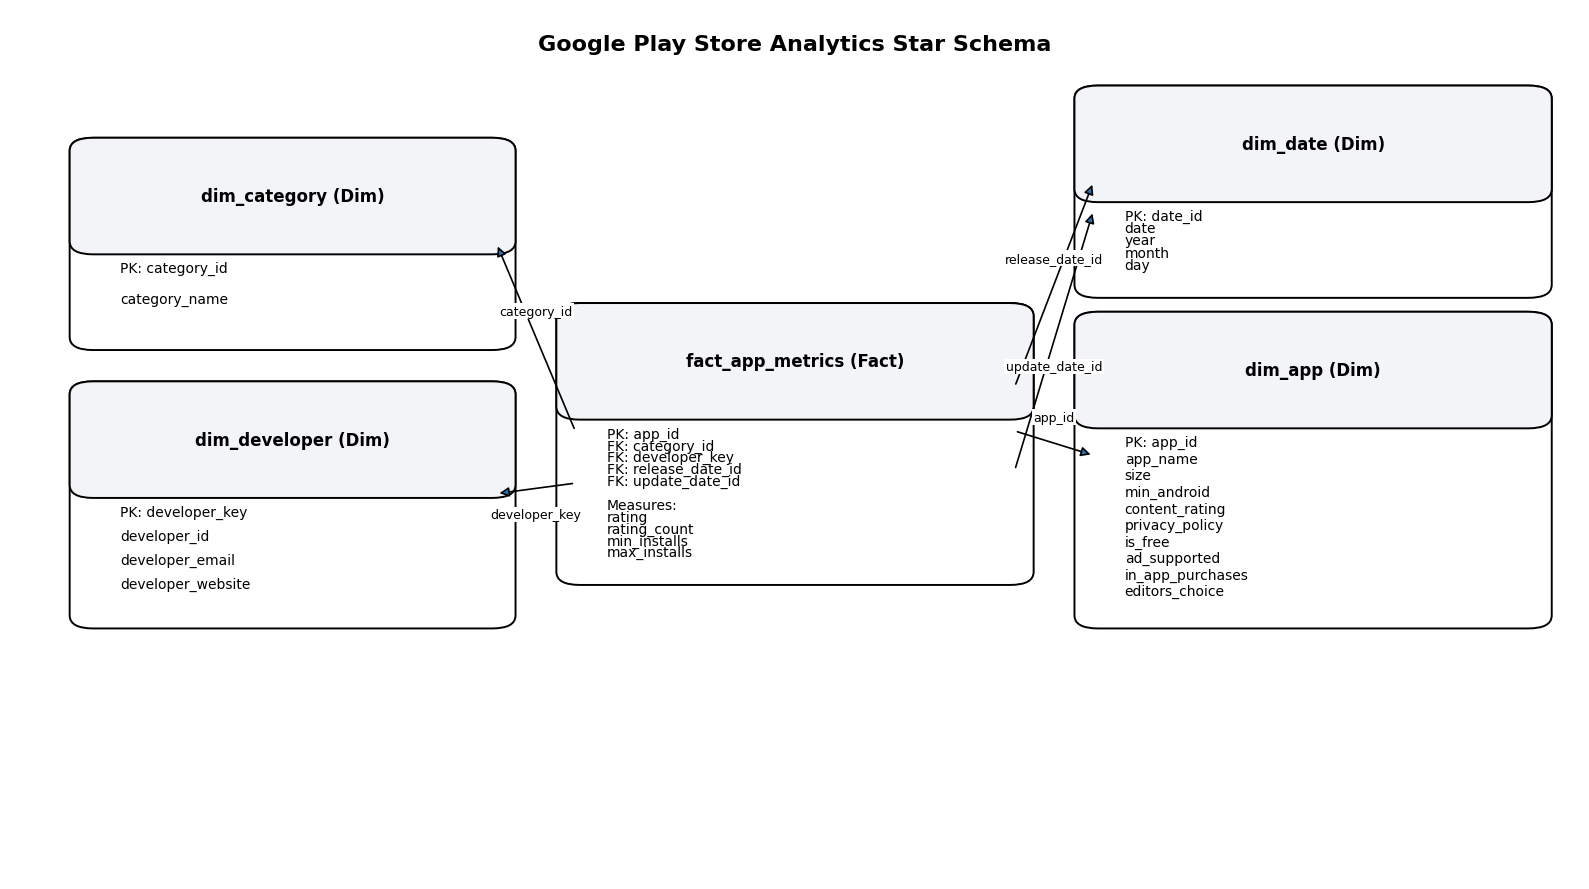

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# ---------- Helpers ----------
def draw_table(ax, x, y, w, h, title, lines, header_height=0.11):
    """
    Draw a rounded table box with a header and bullet lines.
    Coordinates are in axes fraction (0 to 1).
    """
    # Outer box
    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.012,rounding_size=0.015",
        linewidth=1.4, facecolor="white"
    )
    ax.add_patch(box)

    # Header box
    header = FancyBboxPatch(
        (x, y + h - header_height), w, header_height,
        boxstyle="round,pad=0.012,rounding_size=0.015",
        linewidth=1.4, facecolor="#f2f4f7"
    )
    ax.add_patch(header)

    # Header title
    ax.text(
        x + w/2, y + h - header_height/2,
        title, ha="center", va="center",
        fontsize=12, fontweight="bold"
    )

    # Body text
    top = y + h - header_height - 0.02
    line_step = (h - header_height - 0.04) / max(len(lines), 1)

    for i, t in enumerate(lines):
        ax.text(
            x + 0.02, top - i * line_step,
            t, ha="left", va="top",
            fontsize=10
        )

def arrow(ax, x1, y1, x2, y2, label=None, label_offset=(0, 0)):
    a = FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="-|>",
        mutation_scale=14,
        linewidth=1.2
    )
    ax.add_patch(a)

    if label:
        mx, my = (x1 + x2) / 2 + label_offset[0], (y1 + y2) / 2 + label_offset[1]
        ax.text(mx, my, label, fontsize=9, ha="center", va="center", bbox=dict(facecolor="white", edgecolor="none", pad=1))

# ---------- Diagram content ----------
fact_title = "fact_app_metrics (Fact)"
fact_lines = [
    "PK: app_id",
    "FK: category_id",
    "FK: developer_key",
    "FK: release_date_id",
    "FK: update_date_id",
    "",
    "Measures:",
    "rating",
    "rating_count",
    "min_installs",
    "max_installs"
]

cat_title = "dim_category (Dim)"
cat_lines = [
    "PK: category_id",
    "category_name"
]

dev_title = "dim_developer (Dim)"
dev_lines = [
    "PK: developer_key",
    "developer_id",
    "developer_email",
    "developer_website"
]

app_title = "dim_app (Dim)"
app_lines = [
    "PK: app_id",
    "app_name",
    "size",
    "min_android",
    "content_rating",
    "privacy_policy",
    "is_free",
    "ad_supported",
    "in_app_purchases",
    "editors_choice"
]

date_title = "dim_date (Dim)"
date_lines = [
    "PK: date_id",
    "date",
    "year",
    "month",
    "day"
]

# ---------- Layout ----------
fig = plt.figure(figsize=(16, 9))
ax = plt.gca()
ax.set_axis_off()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

# Positions (x, y, width, height)
fact_pos = (0.36, 0.35, 0.28, 0.30)
cat_pos  = (0.05, 0.62, 0.26, 0.22)
dev_pos  = (0.05, 0.30, 0.26, 0.26)
app_pos  = (0.69, 0.30, 0.28, 0.34)
date_pos = (0.69, 0.68, 0.28, 0.22)

# Draw tables
draw_table(ax, *fact_pos, fact_title, fact_lines)
draw_table(ax, *cat_pos,  cat_title,  cat_lines)
draw_table(ax, *dev_pos,  dev_title,  dev_lines)
draw_table(ax, *app_pos,  app_title,  app_lines)
draw_table(ax, *date_pos, date_title, date_lines)

# Connectors (Fact center edges)
fx, fy, fw, fh = fact_pos
fact_left_mid   = (fx, fy + fh * 0.55)
fact_left_low   = (fx, fy + fh * 0.35)
fact_right_mid  = (fx + fw, fy + fh * 0.55)
fact_right_high = (fx + fw, fy + fh * 0.72)
fact_right_low  = (fx + fw, fy + fh * 0.40)

# Category arrow
cx, cy, cw, ch = cat_pos
cat_right_mid = (cx + cw, cy + ch * 0.50)
arrow(ax, fact_left_mid[0], fact_left_mid[1], cat_right_mid[0], cat_right_mid[1], "category_id", (0, 0.03))

# Developer arrow
dx, dy, dw, dh = dev_pos
dev_right_mid = (dx + dw, dy + dh * 0.55)
arrow(ax, fact_left_low[0], fact_left_low[1], dev_right_mid[0], dev_right_mid[1], "developer_key", (0, -0.03))

# App arrow
axp, ayp, aw, ah = app_pos
app_left_mid = (axp, ayp + ah * 0.55)
arrow(ax, fact_right_mid[0], fact_right_mid[1], app_left_mid[0], app_left_mid[1], "app_id", (0, 0.03))

# Date arrows (two relationships to same dim_date)
tx, ty, tw, th = date_pos
date_left_mid  = (tx, ty + th * 0.55)
date_left_low  = (tx, ty + th * 0.40)

arrow(ax, fact_right_high[0], fact_right_high[1], date_left_mid[0], date_left_mid[1], "release_date_id", (0, 0.03))
arrow(ax, fact_right_low[0],  fact_right_low[1],  date_left_low[0], date_left_low[1], "update_date_id", (0, -0.03))

# Title
ax.text(0.5, 0.96, "Google Play Store Analytics Star Schema", ha="center", va="center", fontsize=16, fontweight="bold")

plt.tight_layout()
plt.show()

# Optional: save image to DBFS (FileStore)
out_path = "/dbfs/FileStore/google_play_star_schema.png"

In [2]:
!pip install streamlit -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 63.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 108.1 MB/s eta 0:00:00


In [10]:
import streamlit as st
import pandas as pd
import plotly.express as px

st.set_page_config(
    page_title="Big Data Project Dashboard",
    layout="wide",
    initial_sidebar_state="expanded"
)

top_categories_data = {
    'Category': ['Education', 'Music & Audio', 'Tools', 'Business', 'Entertainment'],
    'App Count': [241086, 154905, 143987, 143770, 138271],
    'Avg Rating': [2.25, 2.23, 2.35, 1.44, 2.44],
    'Avg Installs': [44855, 148620, 510713, 59663, 202064]
}
df_cats = pd.DataFrame(top_categories_data)

top_apps_data = {
    'App Name': ['Samsung Gallery', 'Facebook Lite', 'Samsung My Files', 'Google Messages', 'Google Photos'],
    'Category': ['Photography', 'Social', 'Tools', 'Communication', 'Photography'],
    'Installs (Billions)': [2.12, 2.07, 2.01, 1.95, 1.90],
    'Rating': [4.5, 3.1, 4.3, 4.4, 4.5]
}
df_apps = pd.DataFrame(top_apps_data)

st.sidebar.title("Navigation")

page = st.sidebar.radio("Go to", [
    "1. Executive Overview",
    "2. Product Leaders (Top Apps)",
    "3. Market Strategy Matrix"
])

st.sidebar.info("Project: Google Play Store Analytics")
st.sidebar.markdown("---")
st.sidebar.caption("Big Data Project - Delivery 6")

if page == "1. Executive Overview":
    st.title("Executive Overview & Main KPIs")

    col1, col2, col3, col4 = st.columns(4)
    col1.metric("Total Apps", "2.3 Million", delta="Dataset Size")
    col2.metric("Top Category", "Education", delta="By Count")
    col3.metric("Top Usage", "Tools", delta="By Installs")
    col4.metric("Avg Rating", "2.2 / 5.0", delta="-0.1 vs LY", delta_color="inverse")

    st.markdown("---")

    c1, c2 = st.columns(2)
    with c1:
        fig_supply = px.bar(df_cats, x='Category', y='App Count', color='App Count',
                            title="Most Crowded Categories (Supply)", text_auto='.2s')
        st.plotly_chart(fig_supply, use_container_width=True)
    with c2:
        fig_demand = px.bar(df_cats, x='Category', y='Avg Installs', color='Avg Installs',
                            title="Highest User Demand (Downloads)", text_auto='.2s')
        st.plotly_chart(fig_demand, use_container_width=True)

    st.subheader("User Satisfaction Overview")
    fig_rating = px.bar(df_cats, x='Category', y='Avg Rating', color='Avg Rating',
                        range_y=[0, 5], title="Average Rating per Category")
    fig_rating.add_hline(y=2.2, line_dash="dash", line_color="red", annotation_text="Global Avg")
    st.plotly_chart(fig_rating, use_container_width=True)

elif page == "2. Product Leaders (Top Apps)":
    st.title("Deep Dive: Global Product Leaders")
    st.markdown("Analyzing the top performing applications across the entire ecosystem.")

    fig_apps = px.bar(df_apps, x='Installs (Billions)', y='App Name', orientation='h',
                      color='Category', title="Top 5 Apps by Total Installs", text_auto=True)
    fig_apps.update_layout(yaxis={'categoryorder':'total ascending'})
    st.plotly_chart(fig_apps, use_container_width=True)

    st.caption("Detailed view of top performers:")
    st.dataframe(df_apps, use_container_width=True)

elif page == "3. Market Strategy Matrix":
    st.title("Deep Dive: Strategy & Positioning")
    st.markdown("Understanding the correlation between Market Supply (Count) and User Satisfaction (Rating).")

    fig_scatter = px.scatter(
        df_cats,
        x='App Count',
        y='Avg Rating',
        size='Avg Installs',
        color='Category',
        size_max=60,
        title="Strategy Matrix: Competition vs. Quality",
        hover_name="Category"
    )

    fig_scatter.add_hline(y=2.0, line_dash="dot", annotation_text="Quality Threshold")
    fig_scatter.add_vline(x=150000, line_dash="dot", annotation_text="Saturation Point")

    st.plotly_chart(fig_scatter, use_container_width=True)

    st.info("**How to read this chart:**\n"
            "- **X-Axis:** How crowded the market is.\n"
            "- **Y-Axis:** How happy users are.\n"
            "- **Bubble Size:** Represents the total demand (Installs).")

2025-12-29 17:39:02.335 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-12-29 17:39:02.338 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-12-29 17:39:02.340 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-12-29 17:39:02.341 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-12-29 17:39:02.342 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-12-29 17:39:02.343 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-12-29 17:39:02.346 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-12-29 17:39:02.347 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

In [ ]:
import urllib
print("Password/IP for localtunnel is:", urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip("\n"))

!streamlit run app.py &>/content/logs.txt &

!npx localtunnel --port 8501

Password/IP for localtunnel is: 34.74.63.196
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴your url is: https://famous-rockets-grab.loca.lt
